In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':20})
import os
from scipy.io import loadmat

import sys
sys.path.append('/home/ks2823/SerialDilutionModel/src/')

from Ophelia_evaluation import load_venturelli_arrays, train_model, evaluate_predictions
from SerialDilutionModels import LatentAssemblyModel
import copy
from glob import glob
import torch
import scipy as sp

In [2]:
train_data_red = loadmat('../Data/train_data.mat')
X_train_full = np.array(train_data_red['train_data'])

test_data_red  = loadmat('../Data/test_data.mat')
X_test  = np.array(test_data_red['test_data'])

In [3]:
num_latent_dims = 4

train_test_ratio = 0.8
num_samples = X_train_full.shape[0]

shuffled_idxs = np.arange(num_samples)
np.random.shuffle(shuffled_idxs)

X_train_idxs = shuffled_idxs[:int(train_test_ratio*num_samples)]
X_val_idxs = shuffled_idxs[int(train_test_ratio*num_samples):]

X_train = X_train_full[X_train_idxs]
X_val = X_train_full[X_val_idxs]

In [4]:
train_trajectories, val_trajectories, test_trajectories, num_species, strains, valid_conds = load_venturelli_arrays(X_train, X_val, X_test)

model = LatentAssemblyModel(num_species=num_species, num_latent_dims=num_latent_dims)

model, train_loss_hist, val_loss_hist = train_model(model, train_trajectories=train_trajectories, eval_trajectories=val_trajectories)

Parsing Venturelli datasets...
Extracted 1215 Train, 315 Val, and 73 Test causal trajectories.

Starting Multi-Passage Autoregressive Training...
Epoch    0/1500 | Train KL (Avg/Step): 0.140725 | Val KL (Avg/Step): 0.349365
Epoch  100/1500 | Train KL (Avg/Step): 0.081356 | Val KL (Avg/Step): 0.165559
Epoch  200/1500 | Train KL (Avg/Step): 0.073278 | Val KL (Avg/Step): 0.154171
Epoch  300/1500 | Train KL (Avg/Step): 0.070517 | Val KL (Avg/Step): 0.162291
Epoch  400/1500 | Train KL (Avg/Step): 0.070474 | Val KL (Avg/Step): 0.163344
Epoch  500/1500 | Train KL (Avg/Step): 0.071111 | Val KL (Avg/Step): 0.164938
Epoch  600/1500 | Train KL (Avg/Step): 0.072080 | Val KL (Avg/Step): 0.166788
Epoch  700/1500 | Train KL (Avg/Step): 0.073347 | Val KL (Avg/Step): 0.168790
Epoch  800/1500 | Train KL (Avg/Step): 0.074930 | Val KL (Avg/Step): 0.170318
Epoch  900/1500 | Train KL (Avg/Step): 0.076896 | Val KL (Avg/Step): 0.171091
Epoch 1000/1500 | Train KL (Avg/Step): 0.079352 | Val KL (Avg/Step): 0.171


Successfully predicted 73/73 test sets without NaNs.
Train Scatter | Abundance Log-R^2=0.990
Test t=0 -> t=12h | Model Log-R^2=0.990
Test t=0 -> t=24h | Model Log-R^2=0.991
Test t=0 -> t=36h | Model Log-R^2=0.978
Test t=0 -> t=48h | Model Log-R^2=0.980
Test t=0 -> t=60h | Model Log-R^2=0.966

Saved evaluation plot to 'Images/venturelli_evaluation.png'


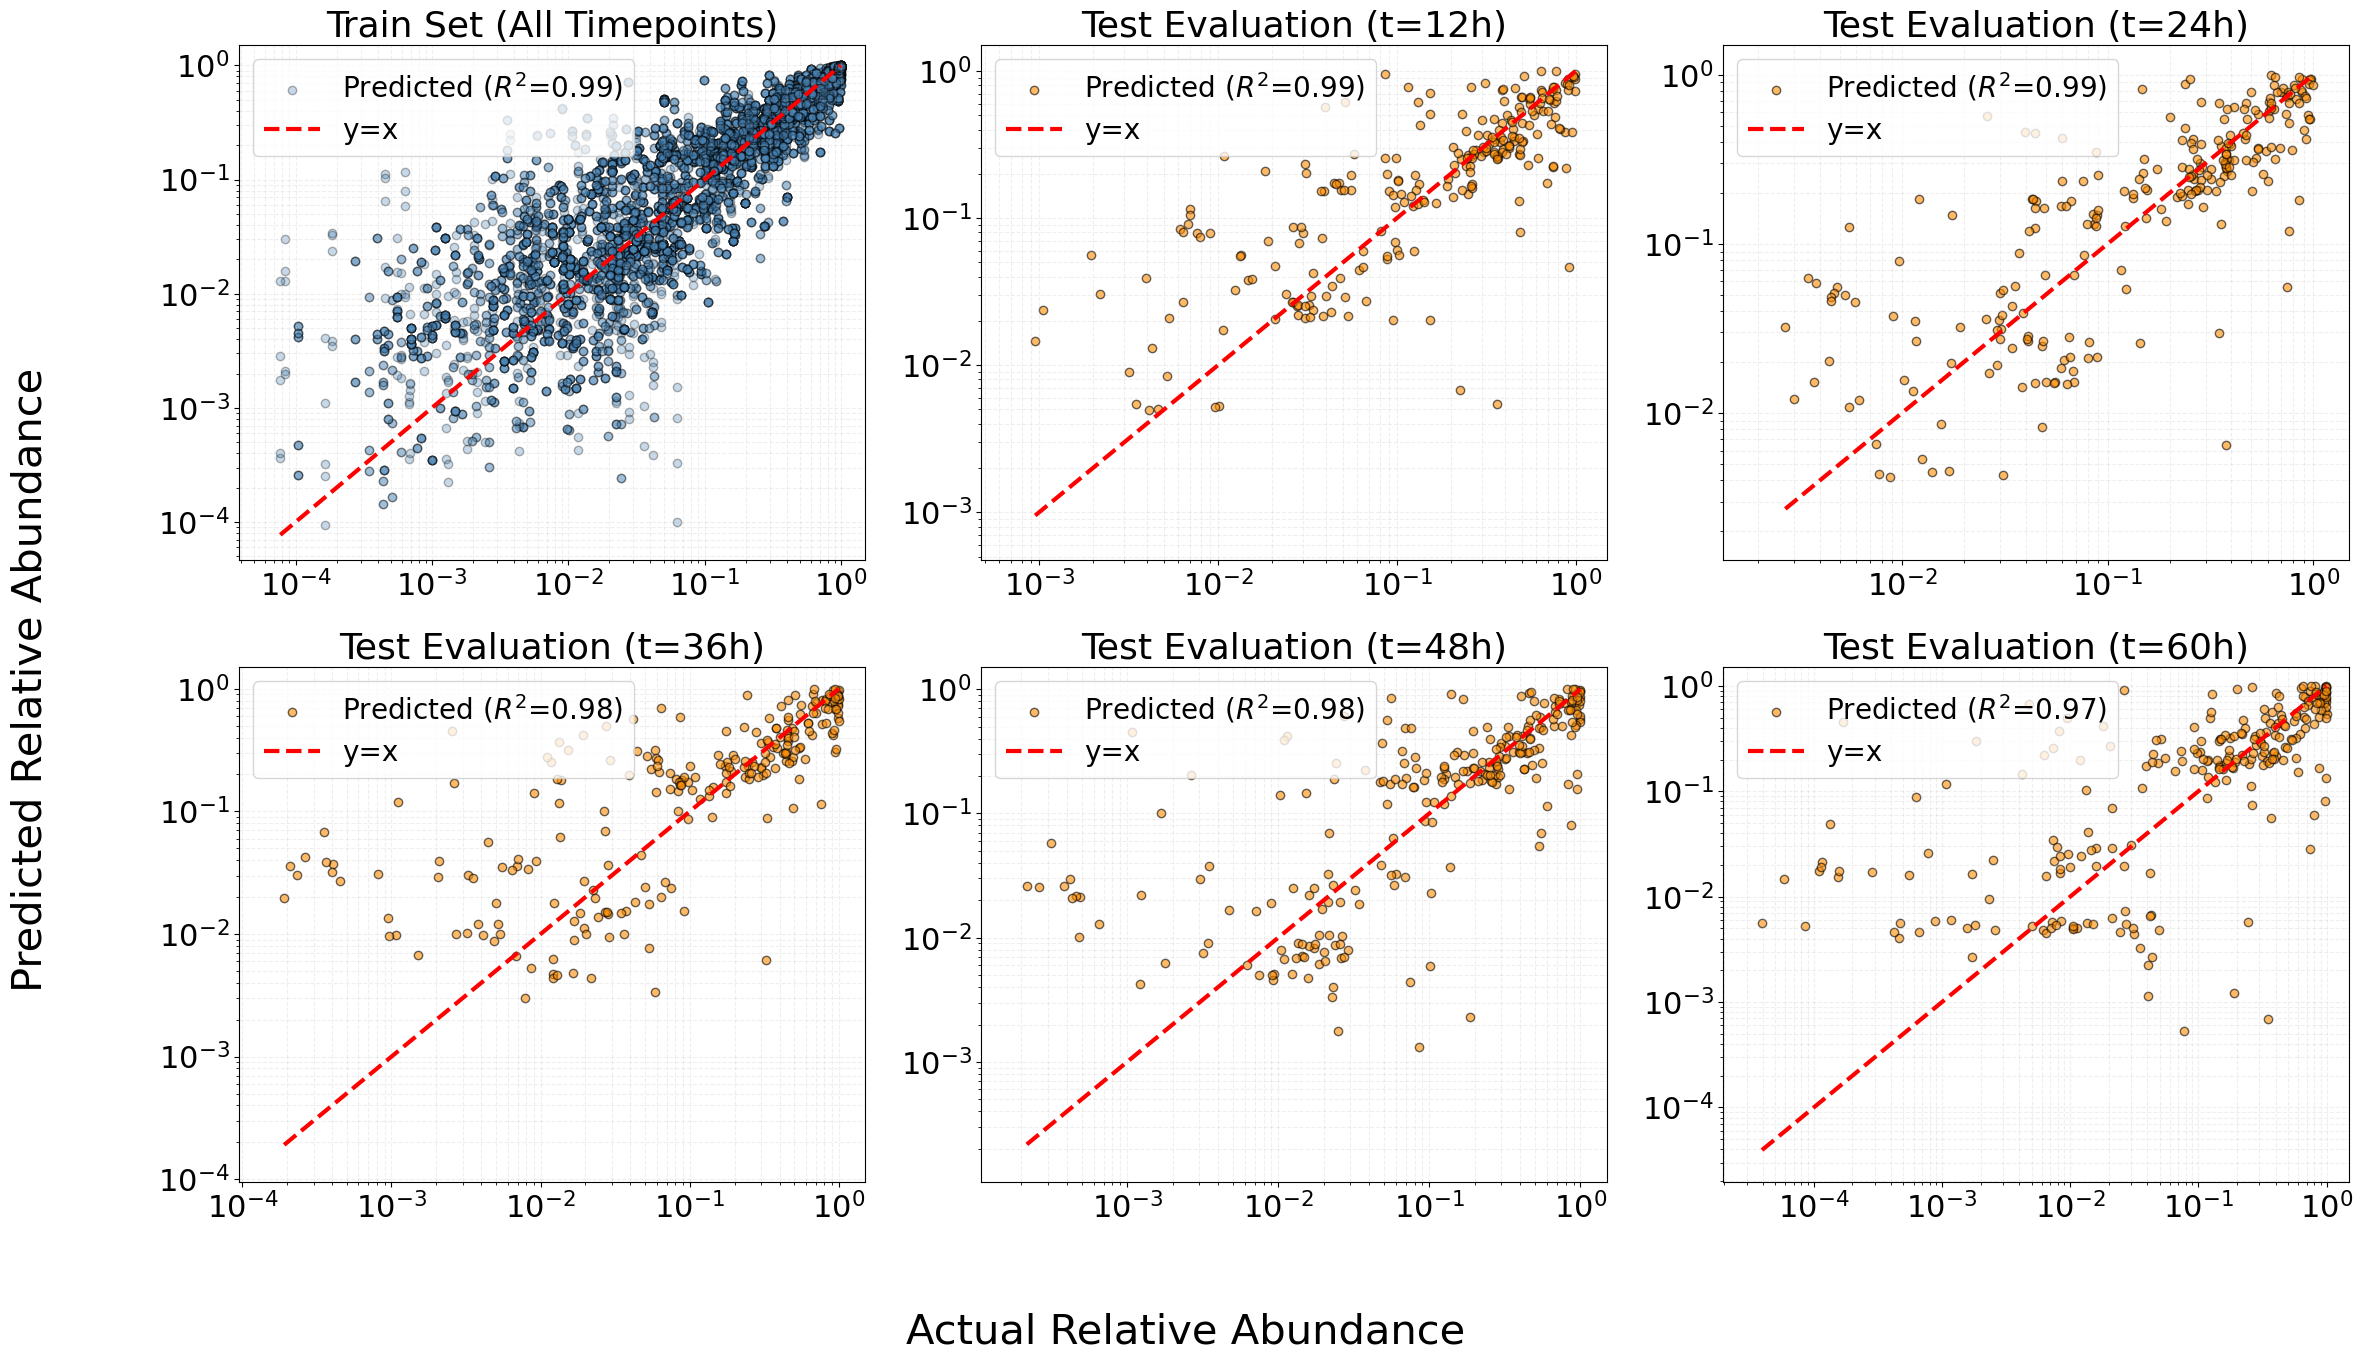

In [5]:
evaluate_predictions(model, train_trajectories=train_trajectories, test_trajectories=test_trajectories, strains=strains, 
                        valid_conds=valid_conds, train_loss_hist=train_loss_hist, val_loss_hist=val_loss_hist, plot_eval=True, 
                        save_data=False)

In [31]:
device = next(model.parameters()).device
X_test_tensor = torch.tensor(X_test[:, 0, :], dtype=torch.float32, device=device)
aux_input = torch.zeros(
            X_test.shape[0], dtype=torch.long, device=device
        )

entropy_diff = []
entropy_ratio = []
test_entropy_list = []
pred_entropy_list = []
for i in range(X_test_tensor.shape[0]):
    inoc_tensor = X_test_tensor[i] 
    steady_state, converged, _ = model.find_steady_state(inoc_tensor, 0, max_passages=200000)
    if converged:
        test_entropy = sp.stats.entropy(X_test[i, -1, :])
        pred_entropy = sp.stats.entropy(steady_state)
        entropy_diff.append(pred_entropy - test_entropy)
        entropy_ratio.append(pred_entropy/test_entropy)
        test_entropy_list.append(test_entropy)
        pred_entropy_list.append(pred_entropy)

In [1]:
model.theta

NameError: name 'model' is not defined

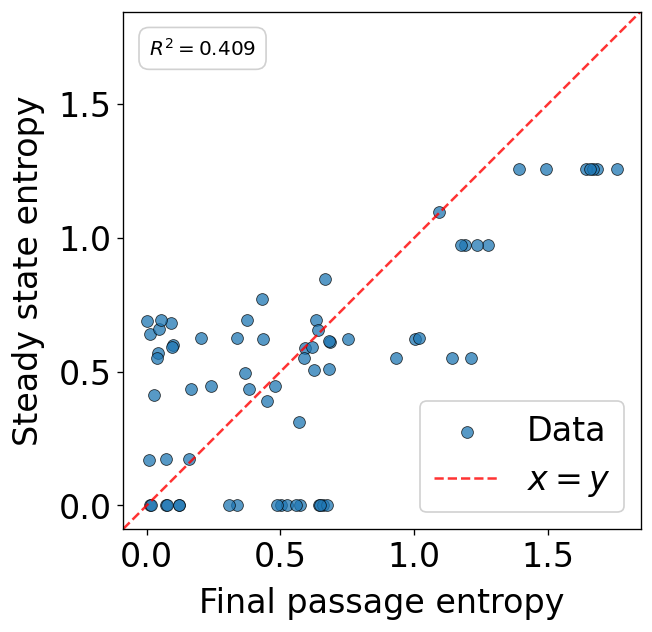

In [39]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score

# Convert lists to numpy arrays
x = np.array(test_entropy_list)
y = np.array(pred_entropy_list)

# 1. Calculate the R^2 score (how well predicted values match test values)
r2 = r2_score(x, y)
# Fallback without scikit-learn: 
# r2 = 1 - np.sum((x - y)**2) / np.sum((x - np.mean(x))**2)

# 2. Set up a high-resolution, square figure
fig, ax = plt.subplots(figsize=(6, 6), dpi=120)

# 3. Plot scatter points with alpha blending and subtle edge colors
ax.scatter(x, y, alpha=0.75, edgecolors='k', linewidth=0.5, s=50, 
           color='#1f77b4', label='Data')

# 4. Calculate dynamic axes limits with a 5% buffer
lim_min = min(x.min(), y.min())
lim_max = max(x.max(), y.max())
margin = (lim_max - lim_min) * 0.05
lims = [lim_min - margin, lim_max + margin]

# 5. Plot the x = y identity line across the full diagonal
ax.plot(lims, lims, 'r--', alpha=0.8, linewidth=1.5, label='$x = y$')

# 6. Display the R^2 score inside a formatted bounding box
textstr = f'$R^2 = {r2:.3f}$'
props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='#cccccc')
ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', bbox=props)

# 7. Apply clean typography, equal aspect ratio, and grid styling
ax.set_xlabel('Final passage entropy', fontsize=20, fontweight='medium', labelpad=8)
ax.set_ylabel('Steady state entropy', fontsize=20, fontweight='medium', labelpad=8)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect('equal')  # Crucial: ensures the x = y line is visually at exactly 45 degrees
# ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

In [15]:
model.eval()
pred_test = []

device = next(model.parameters()).device


x_curr = torch.tensor(X_test[:, 0, :], dtype=torch.float32, device=device)
with torch.no_grad():
    for t in range(1, X_test.shape[1]):
        aux_input = torch.zeros(
            X_test.shape[0], dtype=torch.long, device=device
        )

        # Run model and capture the output
        out = model(x_curr, aux_input)

        # Unpack the tuple: extract just the prediction tensor (usually index 0)
        # if isinstance(out, (tuple, list)):
        x_curr = out[1]
        # # else:
        # x_curr = out

        pred_test.append(x_curr)

In [16]:
pred_test[0].shape

torch.Size([73, 12])

In [19]:
pred_test[-1]

tensor([[0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 6.9129e-02, 0.0000e+00, 9.3087e-01, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         9.9107e-01, 8.9275e-03, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 9.6255e-01,
         0.0000e+00, 3.7450e-02, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 5.2169e-01, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 4.7831e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 7.5429e-01, 2.4571e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 9.9824e-01, 0.0000e+00, 0.0000e+00, 1.7644e-03, 0.0000e+00],
        [0.0000e+00, 5

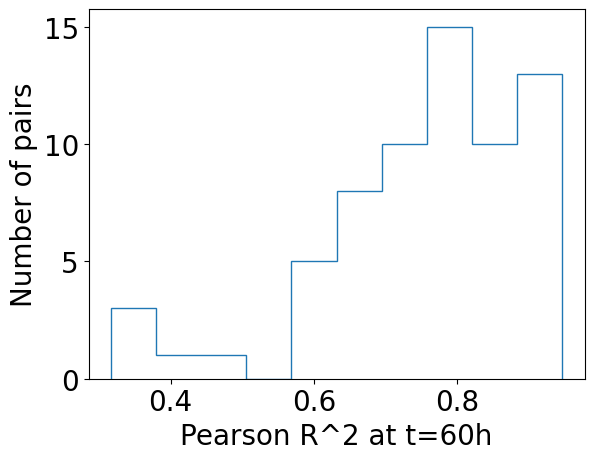

In [29]:
r2_60h = []
for file in glob('../Pairwise_results/*'):
    # print(file)

    data = np.load(file)
    # print(data.files)
    # print(data['r2_t=60h'])
    r2_60h.append(data['r2_t=60h'])

    # break

plt.hist(r2_60h, histtype='step')
plt.xlabel('Pearson R^2 at t=60h')
plt.ylabel('Number of pairs')
plt.show()

### Load plot data

In [2]:
data_dir = '../Results'
data_file = 'venturelli_plot_data.npz'

data_path = os.path.join(data_dir, data_file)
data = np.load(data_path)

In [6]:
for key in data.keys():
    print(key)

train_true
train_pred
r2_train
timepoints_to_plot
test_true
test_pred
true_t=12h
pred_t=12h
r2_t=12h
true_t=24h
pred_t=24h
r2_t=24h
true_t=36h
pred_t=36h
r2_t=36h
true_t=48h
pred_t=48h
r2_t=48h
true_t=60h
pred_t=60h
r2_t=60h


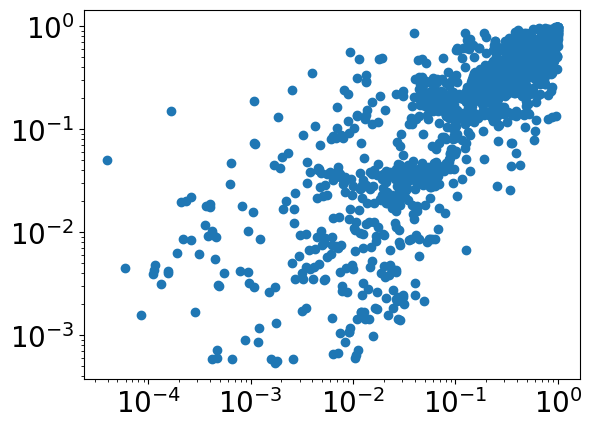

PearsonRResult(statistic=np.float32(0.8298627), pvalue=np.float64(3.481642798077e-312))
PearsonRResult(statistic=np.float32(0.8034699), pvalue=np.float64(9.895761464927464e-278))


/tmp/tmp.TfUm6UZFXB/ipykernel_2716078/575597684.py:14: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  print(sp.stats.pearsonr(np.log(x[mask]), np.log(y[mask])))


In [26]:
x = torch.tensor(data['test_true'])
y = torch.tensor(data['test_pred'])

mask = (x != 0)

# x = torch.clamp(x, 1e-6)
# y = torch.clamp(y, 1e-6)

plt.scatter(x[mask], y[mask])
plt.xscale('log')
plt.yscale('log')
plt.show()
print(sp.stats.pearsonr(x[mask], y[mask]))
print(sp.stats.pearsonr(np.log(x[mask]), np.log(y[mask])))